# Q10: Multiple Linear Regression – Insurance Charges
**Aim:** To build and validate a linear model predicting insurance charges from Age, BMI and children.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("10_Linear_Model_Insurance.csv")
except FileNotFoundError:
    np.random.seed(42)
    age = np.random.randint(18, 65, 50)
    bmi = np.random.normal(28, 5, 50).round(1)
    kids = np.random.randint(0, 5, 50)
    df = pd.DataFrame({"Policyholder_ID": [f"I{i:02d}" for i in range(1, 51)], "Age": age, "BMI": bmi,
                       "Number_of_Children": kids,
                       "Insurance_Charges_INR_Thousand": (5 + 0.6 * age + 0.9 * bmi + 2 * kids + np.random.normal(0, 5, 50)).round(2)})
feats = ["Age", "BMI", "Number_of_Children"]
X, y = df[feats], df["Insurance_Charges_INR_Thousand"]
df.head()

,Policyholder_ID,Age,BMI,Number_of_Children,Insurance_Charges_INR_Thousand
0,I01,56,31.9,2,67.98
1,I02,46,22.5,0,50.28
2,I03,32,33.7,1,58.04
3,I04,60,29.9,1,62.62
4,I05,25,26.1,3,46.18


### 1. EDA: statistics, histograms, scatter plots

In [3]:
df[feats + [y.name]].describe().round(2)

,Age,BMI,Number_of_Children,Insurance_Charges_INR_Thousand
count,50.00,50.00,50.00,50.00
mean,40.14,28.40,2.10,58.68
std,13.28,4.86,1.45,10.86
min,19.00,17.80,0.00,30.82
25%,29.50,24.72,1.00,53.03
50%,39.50,28.65,2.00,58.73
75%,52.25,31.82,3.00,66.54
max,64.00,41.30,4.00,85.61


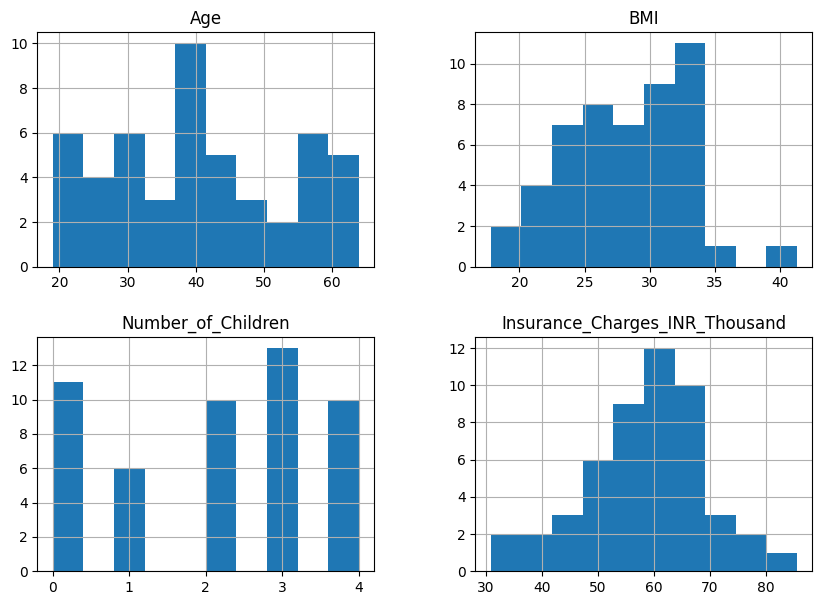

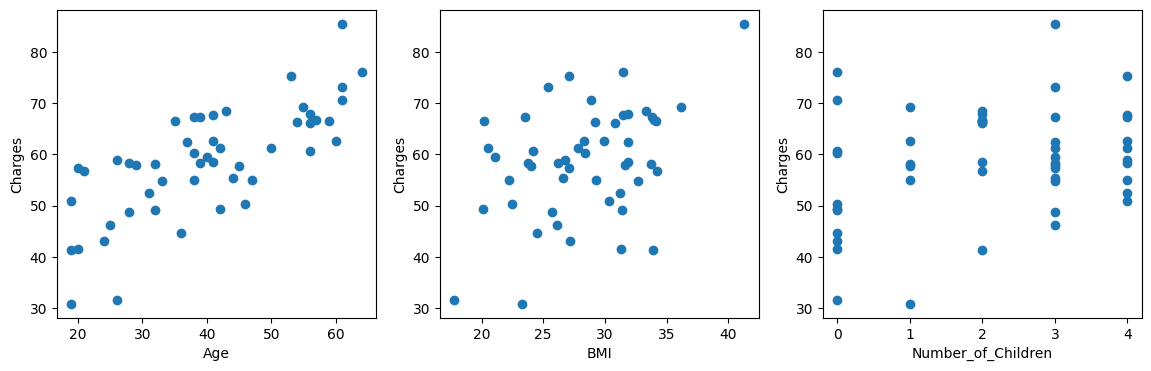

In [4]:
df[feats + [y.name]].hist(bins=10, figsize=(10, 7))
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for i, c in enumerate(feats):
    ax[i].scatter(df[c], y)
    ax[i].set_xlabel(c)
    ax[i].set_ylabel("Charges")
plt.show()

### 2. Multiple linear regression (all data)

In [5]:
full = LinearRegression().fit(X, y)
print("Intercept:", round(full.intercept_, 3))
print(pd.Series(full.coef_, index=feats).round(3))

Intercept: 5.744
Age                   0.631
BMI                   0.762
Number_of_Children    2.830
dtype: float64


### 3. 80:20 split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(40, 3) (10, 3)


### 4. Standardize using training data only, then fit

In [7]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
model = LinearRegression().fit(X_train_s, y_train)

### 5. Coefficients, intercept, R², adjusted R², MAE, MSE, RMSE

In [8]:
def metrics(model, X, y):
    pred = model.predict(X)
    n, k = X.shape
    r2 = r2_score(y, pred)
    mse = mean_squared_error(y, pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - k - 1) if n - k - 1 > 0 else np.nan
    return {"R2": r2, "Adj_R2": adj,
            "MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": np.sqrt(mse)}

print("Intercept:", round(model.intercept_, 3))
print(pd.Series(model.coef_, index=feats, name="Coef (scaled X)").round(3))
pd.DataFrame({"Train": metrics(model, X_train_s, y_train), "Test": metrics(model, X_test_s, y_test)}).round(4)

Intercept: 58.806
Age                   7.196
BMI                   3.824
Number_of_Children    4.337
Name: Coef (scaled X), dtype: float64


,Train,Test
R2,0.8160,0.8022
Adj_R2,0.8006,0.7033
MAE,3.5981,5.1071
MSE,17.0912,40.7266
RMSE,4.1342,6.3817


### 6. Five-fold cross-validation

In [9]:
pipe = make_pipeline(StandardScaler(), LinearRegression())
r2_cv = cross_val_score(pipe, X, y, cv=5, scoring="r2")
rmse_cv = -cross_val_score(pipe, X, y, cv=5, scoring="neg_root_mean_squared_error")
print("R² per fold:", r2_cv.round(3), "| Mean R² =", round(r2_cv.mean(), 3))
print("RMSE per fold:", rmse_cv.round(3), "| Mean RMSE =", round(rmse_cv.mean(), 3))

R² per fold: [0.68  0.744 0.485 0.858 0.787] | Mean R² = 0.711
RMSE per fold: [4.253 6.089 4.524 4.265 5.803] | Mean RMSE = 4.987


### 7. Multicollinearity (VIF)

In [10]:
Xc = sm.add_constant(X)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=feats)
print(vif.round(3))
print("No serious multicollinearity (all VIF < 5)" if (vif < 5).all() else "Multicollinearity present (VIF ≥ 5)")

Age                   1.021
BMI                   1.007
Number_of_Children    1.020
dtype: float64
No serious multicollinearity (all VIF < 5)


### 8. Residual analysis

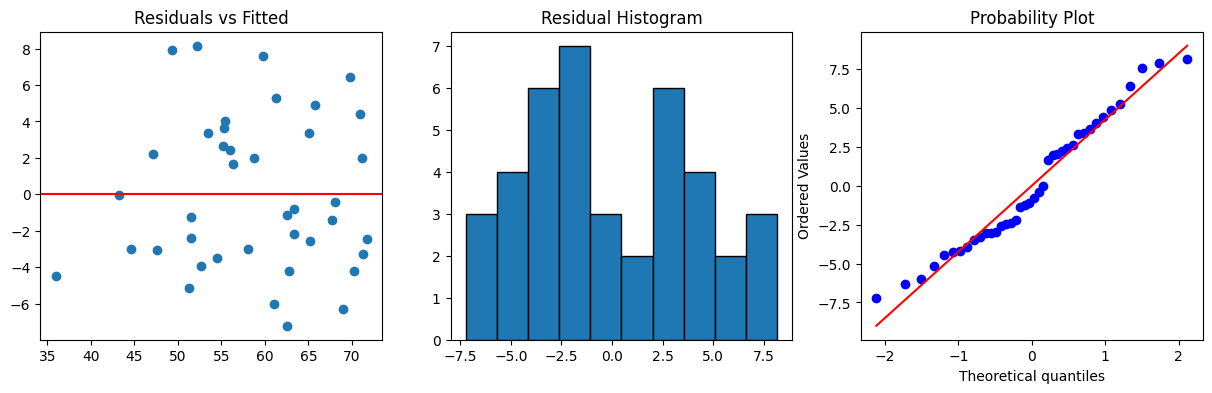

Shapiro-Wilk p = 0.1439 -> Residuals normal


In [11]:
fitted = model.predict(X_train_s)
res = y_train - fitted
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(fitted, res)
ax[0].axhline(0, color="red")
ax[0].set_title("Residuals vs Fitted")
ax[1].hist(res, bins=10, edgecolor="black")
ax[1].set_title("Residual Histogram")
stats.probplot(res, plot=ax[2])
plt.show()
sw_p = stats.shapiro(res).pvalue
print(f"Shapiro-Wilk p = {sw_p:.4f} ->", "Residuals normal" if sw_p > 0.05 else "Not normal")

Random scatter around 0 → linearity and constant variance hold; a funnel shape → heteroscedasticity.

### 9. Standardized coefficients (relative contribution)

In [12]:
beta = pd.Series(model.coef_ / y_train.std(ddof=0), index=feats)
beta.abs().sort_values(ascending=False).round(3)

,0
Age,0.747
Number_of_Children,0.450
BMI,0.397


The predictor with the largest |β| contributes most to insurance charges.

### 10. MLR vs polynomial regression (degree 2)

In [13]:
poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train_s)
Xp_test = poly.transform(X_test_s)
pr = LinearRegression().fit(Xp_train, y_train)
print(pd.DataFrame({"MLR_Test": metrics(model, X_test_s, y_test), "Poly2_Test": metrics(pr, Xp_test, y_test)}).round(4))
poly_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())
print("5-fold CV R²  ->  MLR:", round(r2_cv.mean(), 3), "| Poly2:", round(cross_val_score(poly_pipe, X, y, cv=5, scoring="r2").mean(), 3))

        MLR_Test  Poly2_Test
R2        0.8022      0.8031
Adj_R2    0.7033         NaN
MAE       5.1071      5.1641
MSE      40.7266     40.5280
RMSE      6.3817      6.3662
5-fold CV R²  ->  MLR: 0.711 | Poly2: 0.629


Adj R² is NaN when test rows are too few for the number of polynomial terms, so the CV R² is used for a fair comparison. Higher R² / lower RMSE wins; if similar, keep the simpler MLR.

**Result:** A multiple linear regression model was built, standardized, cross-validated, checked for multicollinearity and residual assumptions, and compared with polynomial regression.